<a href="https://colab.research.google.com/github/Lourdes-Churacutipa/Repositorio-de-lourdes/blob/main/PC3_precipitacion_Santiago_Tuna_share.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PC3 – Evaluación de Productos de Precipitación en la Sierra de Lima
## Estación Santiago de Tuna · Huarochirí · 2926 msnm

| | |
| --- | --- |
| **Curso** | AM4314 – Ciencias de Datos Ambientales |
| **Ciclo** | 2026-I |
| **Temas** | 5.1 Series de tiempo · 5.2 Datos grillados/NetCDF · 6.1 GEE fundamentos |
| **Puntaje total** | 20 puntos |
| **Entrega** | Notebook ejecutado (.ipynb) + precipitacion_Santiago_Tuna.csv |

## Enunciado del problema

### Contexto científico

La cuenca alta del río Rímac abastece de agua potable a más del 30 % de la población del Perú (Lima Metropolitana). Monitorear la precipitación en esta cuenca es crítico para la gestión de reservorios, alertas de inundaciones y planificación ante el cambio climático.

Las redes de estaciones meteorológicas en los Andes son escasas y presentan vacíos temporales. Por ello, los hidrólogos recurren a **productos de precipitación grillados** para reconstruir la variabilidad de la lluvia. Sin embargo, cada producto tiene sesgos propios en zonas de relieve complejo y alta altitud.

### Pregunta de investigación

¿Qué producto de precipitación grillado (PISCOp o ERA5-Land) representa mejor la precipitación observada en la estación Santiago de Tuna (2926 msnm), y cómo se relaciona la precipitación local con el fenómeno El Niño Costero?

### Datos disponibles

| Fuente | Tipo | Período | Resolución |
| --- | --- | --- | --- |
| Estación Santiago de Tuna (472CA750) | Observación puntual (ground truth) | 1964–2014 | Diaria |
| PISCOp (SENAMHI) | Grillado nacional calibrado | 1981–2025 | ~5 km, mensual |
| ERA5-Land (ECMWF) | Reanálisis global | 1950–presente | ~9 km, mensual |
| ICEN (IGP) | Índice Costero El Niño | 1950–presente | Mensual |

### Tareas

1. Cargar los datos observados de la estación y construir una serie mensual de referencia.
2. Extraer la serie mensual de PISCOp en el punto de la estación desde un archivo NetCDF.
3. Extraer la serie mensual de ERA5-Land desde Google Earth Engine.
4. Integrar las tres fuentes en un DataFrame ordenado y exportarlo a CSV.
5. Descargar el índice ICEN del IGP y calcular su correlación con la precipitación observada.
6. Generar gráficos de series de tiempo, diagramas de dispersión y mapa de correlaciones.
7. Evaluar el desempeño de cada producto con métricas estadísticas (r, RMSE, Bias) y concluir.

### Rúbrica

| Sección | Descripción | Puntos |
| --- | --- | --- |
| P0 | Cargar datos observados y obtener serie mensual | 2 |
| P1 | Cargar PISCOp (NetCDF) y extraer serie en el punto | 3 |
| P2 | Extraer ERA5-Land desde GEE + conversión de unidades | 4 |
| P3 | DataFrame unificado (OBS + PISCO + ERA5-Land) y exportar CSV | 2 |
| P4 | Cargar índice ICEN y correlación con OBS | 3 |
| P5 | Visualizaciones: series de tiempo, scatter, heatmap | 4 |
| P6 | Métricas (r, RMSE, Bias) vs OBS y ranking | 2 |
| **Total** | | **20** |

---
## Configuración inicial

Ejecuta las siguientes celdas sin modificar.

In [1]:
# ── Librerías ─────────────────────────────────────────────────────────────────
import ee
import geemap
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import requests
import gdown
import warnings
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive')

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
print("Librerías cargadas ✓")

Mounted at /content/drive
Librerías cargadas ✓


In [2]:
ee.Authenticate()
ee.Initialize(project='ee-lchuracutipa')   # ← reemplaza con tu proyecto GEE
print("GEE inicializado ✓")

GEE inicializado ✓


In [3]:
# ── Parámetros de la estación ─────────────────────────────────────────────────
NOMBRE      = 'Santiago de Tuna'
LAT         = -11.9832    # 11°58'59.6" S
LON         = -76.5242    # 76°31'27.1" W
ALT         = 2926        # msnm
CODIGO      = '472CA750'

PISCO_FILE_ID = '13FvNPV6nCWspgFxG1cBYhem1n2tUKXH6'
OBS_FILE_ID   = '1EKemYnWTc5W-oSv7gBCrcxCKhOYA7nEV'

INICIO = '1981-01-01'
FIN    = '2014-12-31'   # serie observada disponible hasta 2014

print(f"Estación : {NOMBRE}  [{CODIGO}]")
print(f"Lat/Lon  : {LAT}°, {LON}°  |  Alt: {ALT} msnm")
print(f"Período  : {INICIO[:7]} → {FIN[:7]}")

Estación : Santiago de Tuna  [472CA750]
Lat/Lon  : -11.9832°, -76.5242°  |  Alt: 2926 msnm
Período  : 1981-01 → 2014-12


---
## P0 – Datos observados de la estación (2 pts)

Los datos de Santiago de Tuna son el **ground truth**. Todos los productos se evalúan contra esta serie.

Formato del archivo: sin cabecera, separado por espacios.
Columnas: Año | Mes | Día | Precipitación acumulada (mm) | Tmax | Tmin
Valor faltante: -99.9

| Sub-tarea | Puntos |
| --- | --- |
| P0.1 Descargar el archivo con gdown | 0.5 |
| P0.2 Cargar con pandas y aplicar la estructura de columnas correcta | 0.5 |
| P0.3 Construir serie mensual con índice MS y nombre 'OBS' | 1.0 |

In [4]:
# TU CÓDIGO AQUÍ — gdown.download con OBS_FILE_ID, guardar como 'datos_obs.txt'
gdown.download(id=OBS_FILE_ID, output='datos_obs.txt', quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1EKemYnWTc5W-oSv7gBCrcxCKhOYA7nEV
To: /content/datos_obs.txt
100%|██████████| 445k/445k [00:00<00:00, 5.73MB/s]


'datos_obs.txt'

In [5]:
# P0.2 – Cargar con pandas (sin cabecera, separado por espacios) y marcar faltantes
obs_raw = pd.read_csv('datos_obs.txt', sep=r'\s+', header=None,
                      names=['anio', 'mes', 'dia', 'prec', 'tmax', 'tmin'])
obs_raw = obs_raw.replace(-99.9, np.nan)      # -99.9 = valor faltante

print(obs_raw.shape)
print(obs_raw.head())
print("\nFaltantes por columna:")
print(obs_raw.isna().sum())

(18325, 6)
   anio  mes  dia  prec  tmax  tmin
0  1963   12    1   NaN   NaN   NaN
1  1963   12    2   NaN   NaN   NaN
2  1963   12    3   NaN   NaN   NaN
3  1963   12    4   NaN   NaN   NaN
4  1963   12    5   NaN   NaN   NaN

Faltantes por columna:
anio        0
mes         0
dia         0
prec      390
tmax    18325
tmin    18325
dtype: int64


In [6]:
# P0.3 – Serie mensual de referencia (OBS)
obs_raw['fecha'] = pd.to_datetime(dict(year=obs_raw['anio'],
                                       month=obs_raw['mes'],
                                       day=obs_raw['dia']))

# Suma mensual; si el mes tiene menos de 15 días con dato -> NaN
obs_series = (obs_raw.set_index('fecha')['prec']
                     .resample('MS').sum(min_count=15)
                     .rename('OBS'))
obs_series = obs_series.loc[INICIO:FIN]       # período común de análisis

print(f"OBS: {obs_series.index.min():%Y-%m} → {obs_series.index.max():%Y-%m} | "
      f"{len(obs_series)} meses | {obs_series.isna().sum()} NaN")
obs_series.head()

OBS: 1981-01 → 2014-01 | 397 meses | 9 NaN


,OBS
fecha,
1981-01-01,37.1
1981-02-01,121.7
1981-03-01,179.8
1981-04-01,4.4
1981-05-01,0.4


---
## P1 – Datos PISCOp (3 pts)

PISCOp es el producto de referencia de SENAMHI, calibrado con estaciones peruanas.

| Sub-tarea | Puntos |
| --- | --- |
| P1.1 Cargar NetCDF con xarray y mostrar estructura | 0.5 |
| P1.2 Identificar la variable de precipitación y sus unidades | 0.5 |
| P1.3 Extraer serie temporal en el punto con method='nearest' | 1.0 |
| P1.4 Convertir a pd.Series con índice MS y nombre 'PISCO' | 1.0 |

In [7]:
# P1.1 – Descargar y cargar PISCOp (NetCDF)
gdown.download(id=PISCO_FILE_ID, output='pisco.nc', quiet=False)
ds_pisco = xr.open_dataset('pisco.nc')

# La dimensión temporal viene como 'Z1' sin fechas reales -> reconstruirla
ds_pisco = ds_pisco.rename({'Z1': 'time'})
ds_pisco = ds_pisco.assign_coords(
    time=pd.date_range(start='1981-01-01', periods=ds_pisco.sizes['time'], freq='MS')
)
print(ds_pisco)

Downloading...
From: https://drive.google.com/uc?id=13FvNPV6nCWspgFxG1cBYhem1n2tUKXH6
To: /content/pisco.nc
100%|██████████| 56.6M/56.6M [00:00<00:00, 92.4MB/s]


<xarray.Dataset> Size: 79MB
Dimensions:        (time: 540, latitude: 210, longitude: 174)
Coordinates:
  * time           (time) datetime64[ns] 4kB 1981-01-01 ... 2025-12-01
  * latitude       (latitude) float64 2kB 1.95 1.85 1.75 ... -18.85 -18.95
  * longitude      (longitude) float64 1kB -81.35 -81.25 ... -64.15 -64.05
Data variables:
    precipitation  (time, latitude, longitude) float32 79MB ...
    crs            int32 4B ...
Attributes:
    Conventions:   CF-1.4
    created_by:    R packages ncdf4 and terra (version 1.8-70)
    created_date:  2026-05-26 18:28:02


In [8]:
# P1.2 – Variable de precipitación y sus unidades
VAR_PISCO = 'precipitation'
print("Variables  :", list(ds_pisco.data_vars))
print("Dimensiones:", dict(ds_pisco[VAR_PISCO].sizes))
print("Unidades   :", ds_pisco[VAR_PISCO].attrs.get('units', 'no declaradas (PISCOp: mm/mes)'))

Variables  : ['precipitation', 'crs']
Dimensiones: {'time': 540, 'latitude': 210, 'longitude': 174}
Unidades   : mm


In [9]:
# P1.3 – Serie temporal en el punto de la estación (vecino más cercano)
lat_name = 'lat' if 'lat' in ds_pisco.coords else 'latitude'
lon_name = 'lon' if 'lon' in ds_pisco.coords else 'longitude'

pisco_point = ds_pisco[VAR_PISCO].sel({lat_name: LAT, lon_name: LON}, method='nearest')
print(f"Píxel PISCOp seleccionado: lat={float(pisco_point[lat_name]):.3f}, "
      f"lon={float(pisco_point[lon_name]):.3f}  (estación: {LAT}, {LON})")

Píxel PISCOp seleccionado: lat=-11.950, lon=-76.550  (estación: -11.9832, -76.5242)


In [10]:
# P1.4 – Convertir a pd.Series con índice MS y nombre 'PISCO'
pisco_series = pd.Series(
    pisco_point.values,
    index=pd.DatetimeIndex(pisco_point['time'].values).to_period('M').to_timestamp(),
    name='PISCO'
).asfreq('MS').loc[INICIO:FIN]

print(f"PISCO: {len(pisco_series)} meses | {pisco_series.isna().sum()} NaN")
print(pisco_series.describe().round(2))

PISCO: 408 meses | 0 NaN
count    408.00
mean      18.53
std       30.92
min        0.00
25%        0.05
50%        2.18
75%       26.29
max      262.24
Name: PISCO, dtype: float64


---
## P2 – ERA5-Land desde Google Earth Engine (4 pts)

ERA5-Land (ECMWF) es un reanálisis global de alta resolución accesible directamente desde GEE.

| Colección GEE | Banda | Resolución | Unidades originales |
| --- | --- | --- | --- |
| ECMWF/ERA5_LAND/MONTHLY_AGGR | total_precipitation_sum | ~9 km | m/mes → x1000 para mm |

| Sub-tarea | Puntos |
| --- | --- |
| P2.1 Crear punto GEE y filtrar la colección por fecha | 1.0 |
| P2.2 Extraer serie mensual con gee_monthly_ts | 2.0 |
| P2.3 Verificar unidades y estadísticas | 1.0 |

In [11]:
# ── Función auxiliar GEE (proporcionada — no modificar) ──────────────────────
point = ee.Geometry.Point([LON, LAT])

def gee_monthly_ts(collection, band, point, scale, nombre, multiplicador=1.0):
    """Extrae serie temporal mensual de un ee.ImageCollection en un punto."""
    def sample(img):
        val = img.select(band).reduceRegion(
            reducer=ee.Reducer.first(), geometry=point, scale=scale
        ).get(band)
        return ee.Feature(None, {
            'date' : img.date().format('YYYY-MM-dd'),
            'value': ee.Number(val).multiply(multiplicador)
        })
    data = ee.FeatureCollection(collection.map(sample)).getInfo()['features']
    df = pd.DataFrame([
        {'date': f['properties']['date'], 'value': f['properties']['value']}
        for f in data
    ])
    df['date'] = pd.to_datetime(df['date'])
    df = df.sort_values('date').reset_index(drop=True)
    return pd.Series(
        df['value'].values,
        index=pd.DatetimeIndex(df['date']).to_period('M').to_timestamp(),
        name=nombre
    ).asfreq('MS')

print("Función gee_monthly_ts lista ✓")
print(f"Punto GEE: ({LON}, {LAT})")

Función gee_monthly_ts lista ✓
Punto GEE: (-76.5242, -11.9832)


In [12]:
# P2.1 – Colección ERA5-Land mensual filtrada por fecha y banda
era5 = (ee.ImageCollection('ECMWF/ERA5_LAND/MONTHLY_AGGR')
          .filterDate(INICIO, FIN)
          .select('total_precipitation_sum'))
print("Imágenes en la colección:", era5.size().getInfo())   # esperado: 408 (34 años x 12)

Imágenes en la colección: 408


In [13]:
# P2.2 – Extraer la serie en el punto; m -> mm con multiplicador=1000
era5_series = gee_monthly_ts(
    era5, 'total_precipitation_sum', point,
    scale=11132,            # resolución nativa de ERA5-Land (~0.1°)
    nombre='ERA5-Land',
    multiplicador=1000      # m/mes -> mm/mes
)
era5_series = era5_series.loc[INICIO:FIN]
era5_series.head()

,ERA5-Land
date,
1981-01-01,180.127563
1981-02-01,376.100054
1981-03-01,237.785066
1981-04-01,133.106220
1981-05-01,42.477738


In [14]:
# P2.3 – Verificar unidades y estadísticas
print(era5_series.describe().round(2))
print("\nNaN:", era5_series.isna().sum(), "| mínimo >= 0:", bool((era5_series.dropna() >= 0).all()))
# Chequeo de unidades: media mensual de decenas a pocos cientos de mm. Si saliera ~0.1 faltó x1000.

count    408.00
mean     163.36
std      109.63
min        0.14
25%       72.89
50%      148.85
75%      238.85
max      463.44
Name: ERA5-Land, dtype: float64

NaN: 0 | mínimo >= 0: True


---
## P3 – DataFrame unificado y exportación a CSV (2 pts)

Columnas esperadas: OBS | PISCO | ERA5-Land

| Sub-tarea | Puntos |
| --- | --- |
| P3.1 Unir las 3 series alineadas por fecha | 1.0 |
| P3.2 Estadísticas, valores faltantes y exportar CSV | 1.0 |

In [15]:
# P3.1 – Unir las tres series alineadas por fecha (índice MS)
df = pd.concat([obs_series, pisco_series, era5_series], axis=1).loc[INICIO:FIN]
df.index.name = 'fecha'
df = df[['OBS', 'PISCO', 'ERA5-Land']]
print(df.shape)
df.head()

(408, 3)


,OBS,PISCO,ERA5-Land
fecha,,,
1981-01-01,37.1,32.348770,180.127563
1981-02-01,121.7,62.880795,376.100054
1981-03-01,179.8,116.821571,237.785066
1981-04-01,4.4,2.794048,133.106220
1981-05-01,0.4,0.173456,42.477738


In [16]:
# P3.2 – Estadísticas, faltantes y exportación
print(df.describe().round(2))
print("\nValores faltantes:")
print(df.isna().sum())

df.to_csv('precipitacion_Santiago_Tuna.csv', float_format='%.2f', index_label='fecha')
print("\nCSV exportado: precipitacion_Santiago_Tuna.csv ✓")

          OBS   PISCO  ERA5-Land
count  388.00  408.00     408.00
mean    27.98   18.53     163.36
std     50.49   30.92     109.63
min      0.00    0.00       0.14
25%      0.00    0.05      72.89
50%      2.85    2.18     148.85
75%     37.22   26.29     238.85
max    345.00  262.24     463.44

Valores faltantes:
OBS          20
PISCO         0
ERA5-Land     0
dtype: int64

CSV exportado: precipitacion_Santiago_Tuna.csv ✓


---
## P4 – Índice ICEN y correlación con precipitación observada (3 pts)

El [ICEN](http://met.igp.gob.pe/datos/ICEN.txt) (Índice Costero El Niño, IGP) mide anomalías de TSM en la región Niño 1+2 costera.
Valores positivos = El Niño; negativos = La Niña.

| ICEN | Categoría |
| --- | --- |
| mayor o igual a 1.7 | El Niño extraordinario |
| 1.0 – 1.6 | El Niño fuerte |
| 0.4 – 0.9 | El Niño moderado |
| −0.3 – 0.3 | Normal |
| −0.4 a −0.9 | La Niña moderada |
| menor o igual a −1.0 | La Niña fuerte |

| Sub-tarea | Puntos |
| --- | --- |
| P4.1 Descargar y parsear el archivo ICEN del IGP | 1.0 |
| P4.2 Unir al DataFrame; correlación Pearson con OBS | 1.0 |
| P4.3 Scatter OBS vs ICEN coloreado por categoría ENSO | 1.0 |

In [17]:
# P4.1 – Descargar el archivo ICEN del IGP y revisar su formato
URL_ICEN = 'http://met.igp.gob.pe/datos/ICEN.txt'
resp = requests.get(URL_ICEN, timeout=30)
resp.raise_for_status()
texto_icen = resp.text
print("\n".join(texto_icen.splitlines()[:15]))

% Índice Costero El Niño (ICEN; ENFEN, 2024)
% Versión oficial
%Referencia
%ENFEN (2024). Definición operacional de los eventos El Niño Costero y La Niña Costera en el Perú. Nota Técnica.
% yy   mm   ICEN
1950   1   -0.75
1950   2   -1.07
1950   3   -1.25
1950   4   -1.18
1950   5   -1.22
1950   6   -1.05
1950   7   -0.80
1950   8   -0.67
1950   9   -0.49
1950  10   -0.77


In [18]:
# P4.1/P4.2 – Parsear ICEN (año, mes, valor) y unirlo al DataFrame
import re
filas = []
for linea in texto_icen.splitlines():
    m = re.match(r'^\s*(\d{4})\s+(\d{1,2})\s+(-?\d+(?:\.\d+)?)', linea)
    if m:
        filas.append((int(m.group(1)), int(m.group(2)), float(m.group(3))))

icen_df = pd.DataFrame(filas, columns=['anio', 'mes', 'ICEN'])
icen_df.index = pd.to_datetime(dict(year=icen_df['anio'], month=icen_df['mes'], day=1))
icen_df = icen_df[['ICEN']]
assert len(icen_df) > 0, "No se pudo parsear el ICEN: revisa el formato"

def categoria_enso(x):
    if pd.isna(x):  return np.nan
    if x >= 1.7:    return 'El Niño extraordinario'
    if x >= 1.0:    return 'El Niño fuerte'
    if x >= 0.4:    return 'El Niño moderado'
    if x > -0.4:    return 'Normal'          # la tabla deja huecos en 0.3–0.4: se corta en ±0.4
    if x > -1.0:    return 'La Niña moderada'
    return 'La Niña fuerte'

df = df.join(icen_df, how='left')
df['ENSO'] = df['ICEN'].apply(categoria_enso)
print("ICEN unido:", df['ICEN'].notna().sum(), "meses con dato")
print(df['ENSO'].value_counts())

ICEN unido: 408 meses con dato
ENSO
Normal                    127
La Niña moderada          123
El Niño moderado           61
La Niña fuerte             46
El Niño extraordinario     28
El Niño fuerte             23
Name: count, dtype: int64


In [19]:
# P4.2 – Correlación de Pearson OBS vs ICEN (solo meses sin NaN)
tmp = df[['OBS', 'ICEN']].dropna()
r_icen, p_icen = stats.pearsonr(tmp['ICEN'], tmp['OBS'])
print(f"r(OBS, ICEN) = {r_icen:.3f} | p = {p_icen:.4f} | N = {len(tmp)} meses")

r(OBS, ICEN) = 0.048 | p = 0.3430 | N = 388 meses


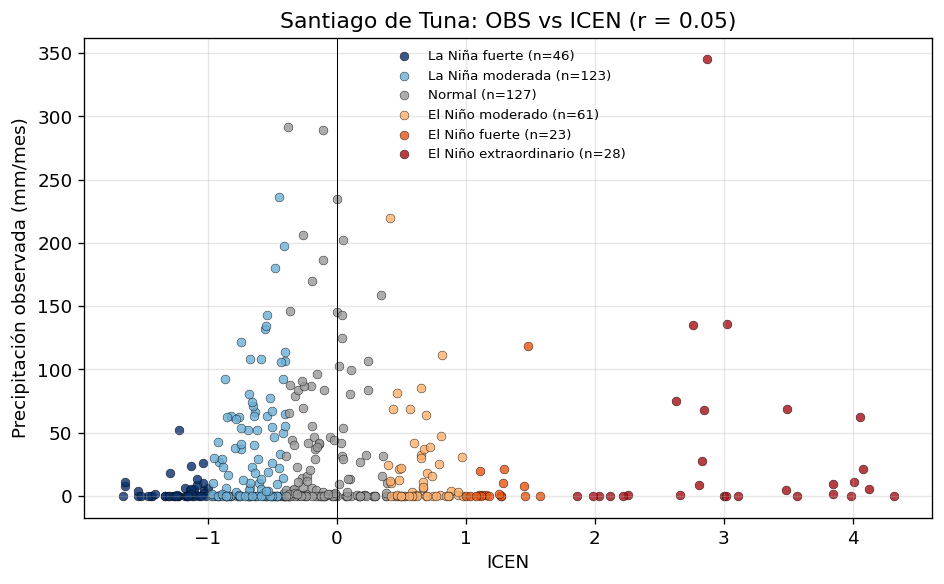

In [20]:
# P4.3 – Scatter OBS vs ICEN coloreado por categoría ENSO
colores = {'La Niña fuerte': '#08306b', 'La Niña moderada': '#6baed6', 'Normal': '#999999',
           'El Niño moderado': '#fdae6b', 'El Niño fuerte': '#e6550d',
           'El Niño extraordinario': '#a50f15'}
fig, ax = plt.subplots(figsize=(8, 5))
for cat, col in colores.items():
    sub = df[df['ENSO'] == cat]
    ax.scatter(sub['ICEN'], sub['OBS'], c=col, label=f"{cat} (n={len(sub)})",
               s=28, alpha=0.8, edgecolor='k', linewidth=0.3)
ax.axvline(0, color='k', lw=0.6)
ax.set_xlabel('ICEN'); ax.set_ylabel('Precipitación observada (mm/mes)')
ax.set_title(f'Santiago de Tuna: OBS vs ICEN (r = {r_icen:.2f})')
ax.legend(fontsize=8, frameon=False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

---
## P5 – Visualizaciones (4 pts)

| Sub-tarea | Puntos |
| --- | --- |
| P5.1 Serie de tiempo: OBS, PISCO y ERA5-Land (1981–2014) | 1.5 |
| P5.2 Scatter de cada producto vs OBS con línea 1:1 y regresión | 1.5 |
| P5.3 Heatmap de correlaciones entre OBS, PISCO, ERA5-Land e ICEN | 1.0 |

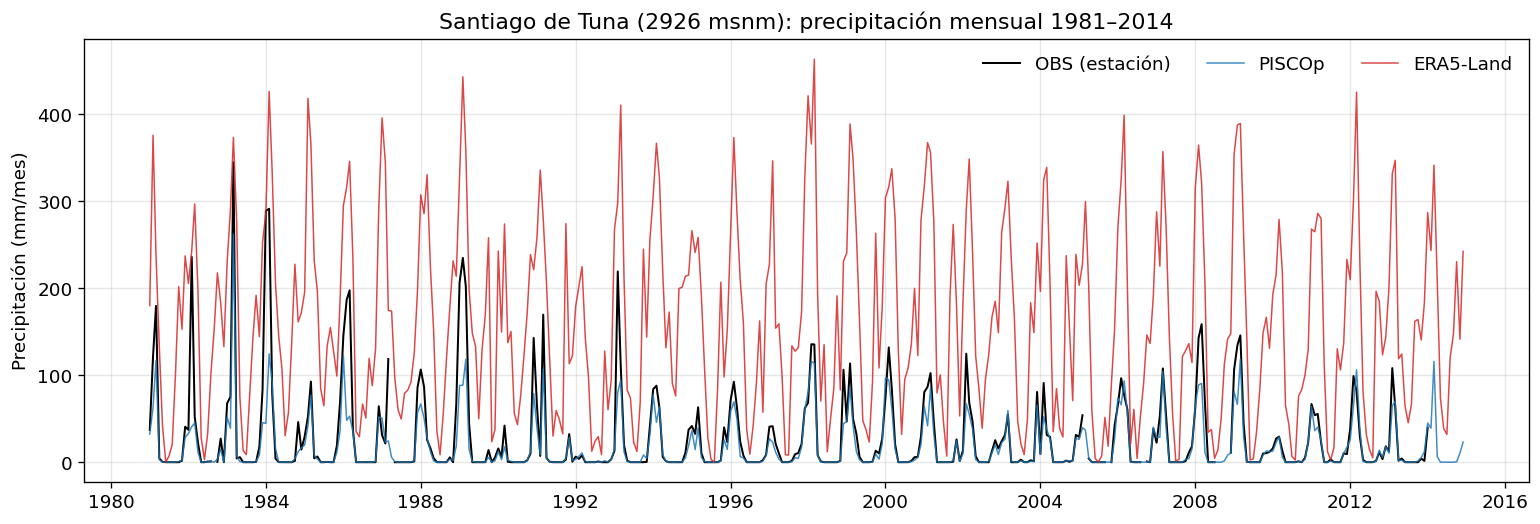

In [21]:
# P5.1 – Series de tiempo OBS, PISCO y ERA5-Land
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(df.index, df['OBS'],       color='k',       lw=1.2, label='OBS (estación)')
ax.plot(df.index, df['PISCO'],     color='#1f77b4', lw=0.9, alpha=0.85, label='PISCOp')
ax.plot(df.index, df['ERA5-Land'], color='#d62728', lw=0.9, alpha=0.85, label='ERA5-Land')
ax.set_ylabel('Precipitación (mm/mes)')
ax.set_title('Santiago de Tuna (2926 msnm): precipitación mensual 1981–2014')
ax.legend(ncol=3, frameon=False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

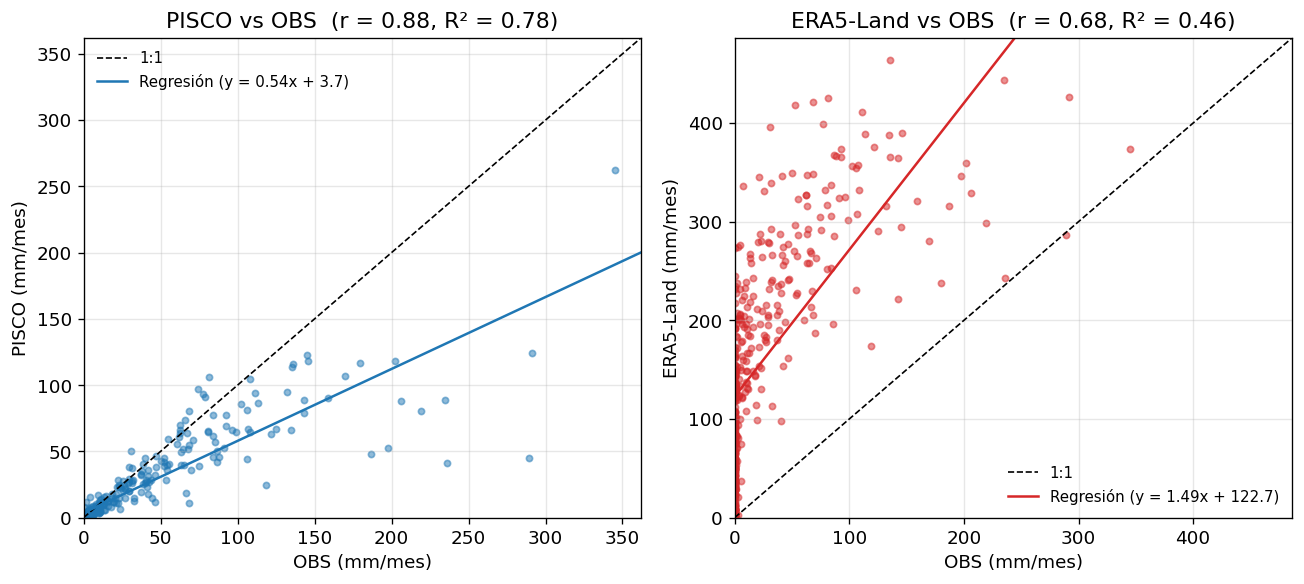

In [22]:
# P5.2 – Scatter de cada producto vs OBS con línea 1:1 y regresión
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, prod, col in zip(axes, ['PISCO', 'ERA5-Land'], ['#1f77b4', '#d62728']):
    t = df[['OBS', prod]].dropna()
    lim = max(t.max().max(), 1) * 1.05
    ax.scatter(t['OBS'], t[prod], s=14, alpha=0.5, color=col)
    ax.plot([0, lim], [0, lim], 'k--', lw=1, label='1:1')
    sl, ic, r, _, _ = stats.linregress(t['OBS'], t[prod])
    xs = np.array([0, lim])
    ax.plot(xs, sl * xs + ic, color=col, lw=1.5, label=f'Regresión (y = {sl:.2f}x + {ic:.1f})')
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_xlabel('OBS (mm/mes)'); ax.set_ylabel(f'{prod} (mm/mes)')
    ax.set_title(f'{prod} vs OBS  (r = {r:.2f}, R² = {r**2:.2f})')
    ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

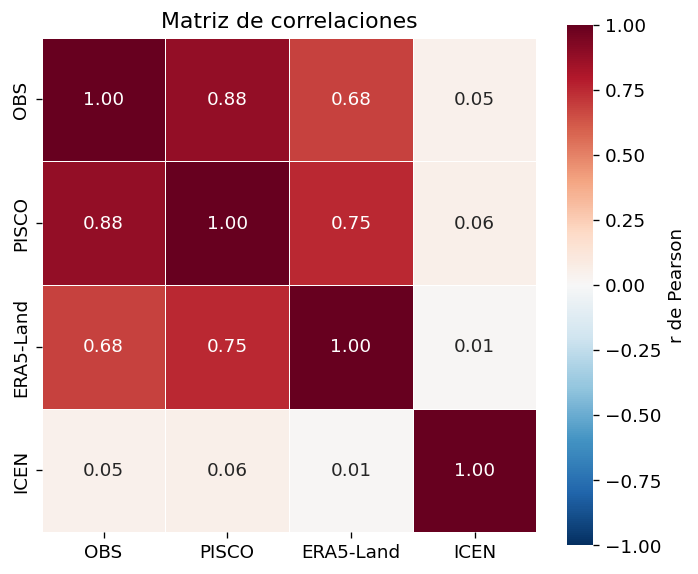

In [23]:
# P5.3 – Heatmap de correlaciones entre OBS, PISCO, ERA5-Land e ICEN
corr = df[['OBS', 'PISCO', 'ERA5-Land', 'ICEN']].corr(method='pearson')
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={'label': 'r de Pearson'}, ax=ax)
ax.set_title('Matriz de correlaciones')
plt.tight_layout(); plt.show()

---
## P6 – Métricas de evaluación y ranking (2 pts)

Para cada producto respecto a OBS:
- **r** — Correlación de Pearson (ideal = 1)
- **RMSE** — Raíz del error cuadrático medio en mm/mes (ideal = 0)
- **Bias** — media(producto) − media(OBS) en mm/mes (ideal = 0)

| Sub-tarea | Puntos |
| --- | --- |
| P6.1 Calcular r, RMSE y Bias para PISCO y ERA5-Land | 1.0 |
| P6.2 Tabla resumen y ranking | 1.0 |

In [24]:
# Función de métricas (proporcionada)
def metricas(df, sim_col, obs_col='OBS'):
    tmp = df[[obs_col, sim_col]].dropna()
    o, s = tmp[obs_col].values, tmp[sim_col].values
    r, _  = stats.pearsonr(o, s)
    rmse  = np.sqrt(np.mean((s-o)**2))
    bias  = s.mean() - o.mean()
    return {'r': round(r,3), 'RMSE (mm/mes)': round(rmse,1),
            'Bias (mm/mes)': round(bias,1), 'N meses': len(tmp)}

In [25]:
# P6.1 – Métricas de cada producto vs OBS
tabla = pd.DataFrame({'PISCOp': metricas(df, 'PISCO'),
                      'ERA5-Land': metricas(df, 'ERA5-Land')}).T
tabla

,r,RMSE (mm/mes),Bias (mm/mes),N meses
PISCOp,0.881,28.8,-9.1,388.0
ERA5-Land,0.681,160.4,136.4,388.0


In [26]:
# P6.2 – Ranking (menor RMSE = mejor); se reportan también r y Bias
ranking = tabla.sort_values('RMSE (mm/mes)').copy()
ranking.insert(0, 'Ranking', range(1, len(ranking) + 1))
print(ranking)
print(f"\nMejor producto según RMSE: {ranking.index[0]}")

           Ranking      r  RMSE (mm/mes)  Bias (mm/mes)  N meses
PISCOp           1  0.881           28.8           -9.1    388.0
ERA5-Land        2  0.681          160.4          136.4    388.0

Mejor producto según RMSE: PISCOp


In [27]:
# Evidencia numérica para las conclusiones (P7)
orden = ['La Niña fuerte', 'La Niña moderada', 'Normal',
         'El Niño moderado', 'El Niño fuerte', 'El Niño extraordinario']
resumen_enso = (df.dropna(subset=['OBS', 'ENSO'])
                  .groupby('ENSO')['OBS'].agg(['count', 'mean', 'max', 'min'])
                  .reindex(orden).round(1))
print("OBS por categoría ENSO (mm/mes):")
print(resumen_enso)

print(f"\nr(OBS, ICEN) = {r_icen:.3f} (p = {p_icen:.4f})")
print("Mejor producto (menor RMSE):", ranking.index[0])

print("\nCiclo estacional medio (mm/mes):")
print(df[['OBS', 'PISCO', 'ERA5-Land']].groupby(df.index.month).mean().round(1).T)

OBS por categoría ENSO (mm/mes):
                        count  mean    max  min
ENSO                                           
La Niña fuerte             45   4.8   52.2  0.0
La Niña moderada          122  30.6  236.1  0.0
Normal                    121  38.0  291.4  0.0
El Niño moderado           54  21.4  219.3  0.0
El Niño fuerte             18  10.1  118.7  0.0
El Niño extraordinario     28  35.0  345.0  0.0

r(OBS, ICEN) = 0.048 (p = 0.3430)
Mejor producto (menor RMSE): PISCOp

Ciclo estacional medio (mm/mes):
fecha              1           2           3      4      5     6     7     8   \
OBS         60.700000   99.500000   96.200000   21.7    1.5   0.0   0.2   0.1   
PISCO       45.400002   52.099998   72.699997   14.9    0.8   0.0   0.1   0.1   
ERA5-Land  263.400000  314.500000  323.400000  213.2  102.7  52.0  28.9  52.0   

fecha         9      10     11          12  
OBS          0.5    3.2   10.8   36.900000  
PISCO        0.3    2.8    7.8   25.299999  
ERA5-Land  116.3  

---
## P7 – Conclusiones (2 pts)

Responde en 200–350 palabras apoyando cada afirmación con métricas o gráficos.

1. **Mejor producto**: ¿PISCOp o ERA5-Land? Justifica con r, RMSE y Bias.
2. **Limitaciones por altitud**: dificultades de los grillados a 2926 msnm.
3. **Relación ENSO–precipitación**: signo de la correlación OBS–ICEN y mecanismo físico.
4. **Fases ENSO extremas**: en qué categorías se registran máximos y mínimos de precipitación.

### Conclusiones

1. Mejor producto: PISCOp representa mejor la precipitación observada. Con 388 meses comparables obtiene r = 0.881, RMSE = 28.8 mm/mes y Bias = −9.1 mm/mes, frente a r = 0.681, RMSE = 160.4 mm/mes y Bias = +136.4 mm/mes de ERA5-Land. Este reproduce el ciclo estacional, pero sobreestima casi seis veces la media (163 vs 28 mm/mes) y marca 30–50 mm en meses secos donde la estación registra cerca de 0.

2. Limitaciones por altitud: A 2926 msnm, en una ladera de relieve abrupto, un píxel de 5–9 km promedia la topografía y no captura la altitud ni la lluvia orográfica de la estación. En ERA5-Land, que no asimila pluviómetros, esto se ve en la regresión (pendiente 1.49, intercepto +122.7 mm), lejos de la línea 1:1. PISCOp subestima los meses más lluviosos (pendiente 0.54) y depende de una red andina escasa; si la estación participó en su calibración, la evaluación no es independiente.

3. Relación ENSO–precipitación: La correlación OBS–ICEN es prácticamente nula (r = 0.048; p = 0.343; N = 388) y no significativa. El ICEN mide la TSM costera (Niño 1+2); una costa más cálida aumenta la humedad y la convección cerca del mar, pero la lluvia en la vertiente occidental andina depende también del flujo del este y de la circulación regional, así que la señal se diluye.

4. Fases ENSO extremas: El máximo absoluto (345 mm/mes, el pico de 1983 en la serie) ocurrió en El Niño extraordinario, cuya media (35.0 mm) es similar a la de Normal (38.0 mm, la más alta). La media más baja corresponde a La Niña fuerte (4.8 mm; máximo 52.2 mm). Hay que tomarlo con cautela: son pocos meses (45, 18 y 28 en La Niña fuerte, El Niño fuerte y El Niño extraordinario) y las medias mezclan la estacionalidad, por lo que conviene comparar anomalías mensuales.